### Trying out a linear model: 

There have been a few great scripts on xgboost already so I'd figured I'd try something simpler: a linear regression model. Surprisingly it does really well with very little feature engineering. The key point is to to log_transform the numeric variables since most of them are skewed.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

%config InlineBackend.figure_format = 'svg'
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
train = pd.read_csv("../input/train.csv")
test = pd.read_csv("../input/test.csv")

In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
all_data = pd.concat((train.loc[:,'MSSubClass':'SaleCondition'],
                      test.loc[:,'MSSubClass':'SaleCondition']))

###Data preprocessing: 
We're not going to do anything fancy here: 
 
- First I'll transform all numeric features by taking log(feature + 1) - this will make the features more normal    
- Create Dummy variables for the categorical features         
- Replace the numeric missing values (NaN's) with the mean of their respective columns

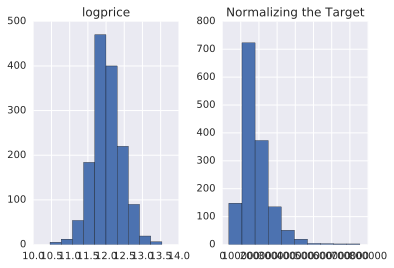

In [5]:
prices = pd.DataFrame({"price":train["SalePrice"], "logprice":np.log1p(train["SalePrice"])})
prices.hist()
plt.title("Normalizing the Target")

In [6]:
#log transform numeric features:
train["SalePrice"] = np.log1p(train["SalePrice"])
types = all_data.dtypes
all_data.loc[:,types[types != "object"].index] = np.log1p(all_data.loc[:,types[types != "object"].index])

In [7]:
all_data = pd.get_dummies(all_data)

In [8]:
#filling NA's with the mean of the column:
all_data = all_data.fillna(all_data.mean())

In [9]:
X_train = all_data[:train.shape[0]].values
X_test = all_data[train.shape[0]:].values
y = train.SalePrice

###Models

Now we are going to use a regularized linear regression model called Ridge from the scikit learn module. This model has a main tuning parameter called alpha so we will create a function that gives us the rmse cross validation score and then use it to see what the best alpha is.

In [10]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import cross_val_score

def rmse_cv(model):
    rmse= np.sqrt(-cross_val_score(model, X_train, y, scoring="mean_squared_error", cv = 5))
    return(rmse)

In [11]:
#model = RidgeCV(alphas = (0.05, 0.1, 0.3, 1, 3, 10, 15, 30, 50, 75),store_cv_values = True)
#model.fit(X_train, y)

In [12]:
model.alpha_

NameError: name 'model' is not defined

In [13]:
rmse_cv(model_ridge).mean()

NameError: name 'model_ridge' is not defined

In [14]:
alphas = [0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 50, 75]
cv_ridge = [rmse_cv(Ridge(alpha = alpha)).mean() 
            for alpha in alphas]

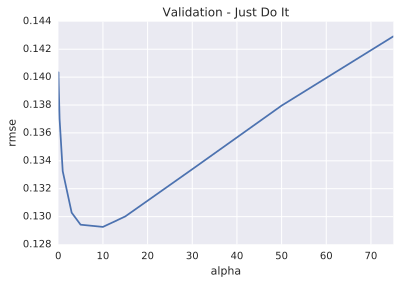

In [15]:
cv_ridge = pd.Series(cv_ridge, index = alphas)
cv_ridge.plot(title = "Validation - Just Do It")
plt.xlabel("alpha")
plt.ylabel("rmse")

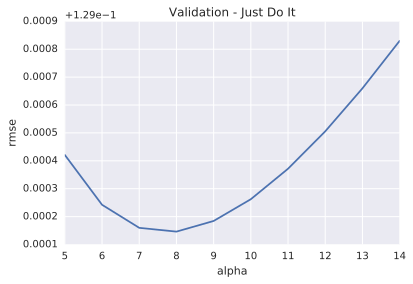

In [16]:
#zooming in on values around 10:
alphas = np.arange(5,15)
cv_ridge = [rmse_cv(Ridge(alpha = alpha)).mean() 
            for alpha in alphas]
cv_ridge = pd.Series(cv_ridge, index = alphas)
cv_ridge.plot(title = "Validation - Just Do It")
plt.xlabel("alpha")
plt.ylabel("rmse")

In [17]:
cv_ridge

5     0.129421
6     0.129242
7     0.129160
8     0.129146
9     0.129184
10    0.129262
11    0.129372
12    0.129506
13    0.129660
14    0.129830
dtype: float64

In [18]:
best_alpha = cv_ridge.argmin()

In [19]:
best_alpha

8

It looks like 8 is the best alpha!

In [20]:
model_ridge = Ridge(alpha = best_alpha).fit(X_train, y)

In [21]:
preds = np.expm1(model_ridge.predict(X_test))

In [22]:
solution = pd.DataFrame({"id":test.Id, "SalePrice":preds})
solution.to_csv("ridge_sol.csv", index = False)